In [1]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/ImagesML/'

Mounted at /content/drive


In [2]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

In [3]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []

    for folder in p.glob('*'):
        label = folder.name

        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))

    return img_list

train_dir = BASE + 'training/'
test_dir = BASE + 'test/'

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print(len(train_img), len(test_img))

240 160


In [4]:
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []

    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))

    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img, y_test = preprocess(test_img)

In [5]:
def extract_hog(X_imgs):
    feats = []

    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8, 8),
                       cells_per_block=(2, 2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)

        feats.append(hog_feat)

    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat = extract_hog(X_test_img)

print(X_train_feat.shape, X_test_feat.shape)

(240, 34596) (160, 34596)


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

In [8]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.8229 - loss: 1.0380 - val_accuracy: 0.9792 - val_loss: 0.2291
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.9844 - loss: 0.0895 - val_accuracy: 0.9792 - val_loss: 0.4495
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.9948 - loss: 0.0081 - val_accuracy: 0.9792 - val_loss: 0.5436
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 1.0000 - loss: 8.8731e-06 - val_accuracy: 0.9792 - val_loss: 0.5863
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 4.4468e-06 - val_accuracy: 0.9792 - val_loss: 0.6090
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 1.0000 - loss: 2.0892e-06 - val_accuracy: 0.9792 - val_loss: 0.6216
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 1.0000 - loss: 1.8409e-06 - val_accuracy: 0.9792 - val_loss: 0.6286
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 2.7270e-06 - val_accuracy: 0.979

In [10]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)

print('Test Accuracy:', test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9000 - loss: 1.1918
Test Accuracy: 0.8999999761581421


In [11]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step
              precision    recall  f1-score   support

           0       0.85      0.97      0.91        80
           1       0.97      0.82      0.89        80

    accuracy                           0.90       160
   macro avg       0.91      0.90      0.90       160
weighted avg       0.91      0.90      0.90       160

[[78  2]
 [14 66]]


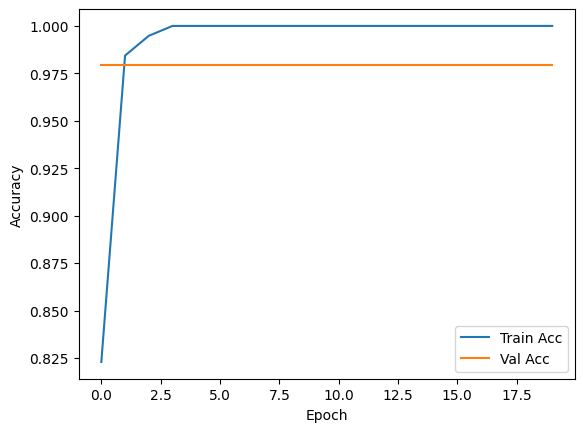

In [12]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [13]:
model.save('day_night_classifier_model.h5')

### Analysis – Lab 4

**Answer:** Test accuracy is **0.9125**; 13 day images were classified as night. The training accuracy reaches 1.0 after about 3 epochs, while the validation loss rises from 0.0016 to about 0.75. This means the model **overfits**: it has 34,596 features for only 192 training images. Training for 2 to 3 epochs would be enough.